## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [6]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ryan Fang

**Date:** 10/19/2026

In [7]:
# Your Phase 1 solution to the problem goes here.

# Q1:

Top 15 most common tokens:


,token,count
0,new,1365
1,date,1202
2,get,1052
3,please,1022
4,enron,927
5,like,923
6,2002,869
7,would,806
8,one,798
9,message,795


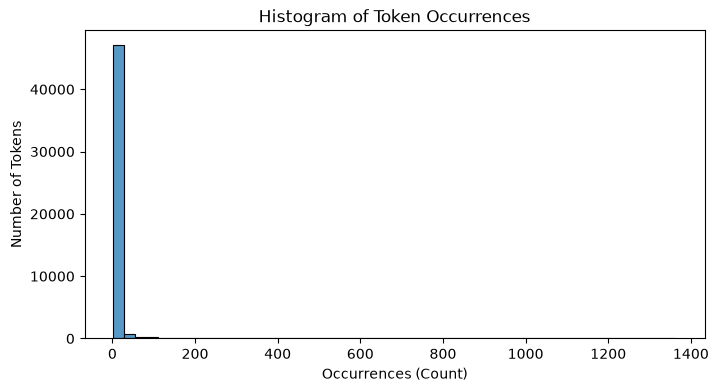

In [13]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

# convert to a DataFrame to inspect and plot
gdf_tokens = pd.DataFrame(token_freq, columns=['token', 'count'])
print("Top 15 most common tokens:")
display(gdf_tokens.head(15))

# plot a histogram of token occurrences
plt.figure(figsize=(8, 4))
sns.histplot(data=gdf_tokens, x='count', bins=50)
plt.title("Histogram of Token Occurrences")
plt.xlabel("Occurrences (Count)")
plt.ylabel("Number of Tokens")
plt.show()


The distribution as seen in the histogram is very right-skewed with a very long tail. The vast majority of tokens appear only a handful of times across the dataset, crowding the histogram into the first bin near zero, while a very small number of common words (such as "new", "date", "get", "please", and "enron") occur thousands of times on the far right.

# Q2:

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import pandas as pd

df = pd.read_parquet('data/Phishing_clean.parquet')

# separate features (one-hot-encoded tokens) and target (Email Type)
X = df.drop('Email Type', axis=1)
y = df['Email Type']

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

# linear regression of y on the one-hot-encoded emails
reg = LinearRegression().fit(X_train, y_train)

r2_train = reg.score(X_train, y_train)
r2_test = reg.score(X_test, y_test)

print(f"Training R^2: {r2_train:.4f}")
print(f"Test R^2: {r2_test:.4f}")

# finding teh words with the largest coefficients in absolute value
coef_df = pd.DataFrame({
    'word': X.columns,
    'coefficient': reg.coef_,
    'abs_coefficient': np.abs(reg.coef_)
}).sort_values(by='abs_coefficient', ascending=False)

print("\nTop 15 words with the largest coefficients in absolute value:")
display(coef_df.head(15))

Training R^2: 0.7680
Test R^2: 0.6588

Top 15 words with the largest coefficients in absolute value:


,word,coefficient,abs_coefficient
1504,background-image:,-0.891476,0.891476
740,localized,0.815698,0.815698
1406,"helvetica,",0.717349,0.717349
2362,thermal,0.706216,0.706216
906,aging,0.622411,0.622411
2566,transcript,0.578132,0.578132
2559,april's,-0.546313,0.546313
1494,retrieving,-0.527824,0.527824
818,cnet,-0.510492,0.510492
2657,zdnet,-0.503465,0.503465


1. The data was split 80/20 into training and testing sets using `train_test_split`.
2. On the training set, the $R^2$ is **0.7680**, while on the test set, the $R^2$ drops to **0.6588**. Because there are 2,711 token features, the linear regression model overfits to the training sample, causing performance to dip.
3. The words with the largest coefficients in absolute value are **`background-image:`** (-0.8915), **`localized`** (0.8157), **`helvetica,`** (0.7173), **`thermal`** (0.7062), and **`aging`** (0.6224). Because many tokens (such as HTML/CSS formatting tags and specific spam keywords) are correlated with one another, ordinary least squares assigns large positive and negative weights to individual tokens.

# Q3:

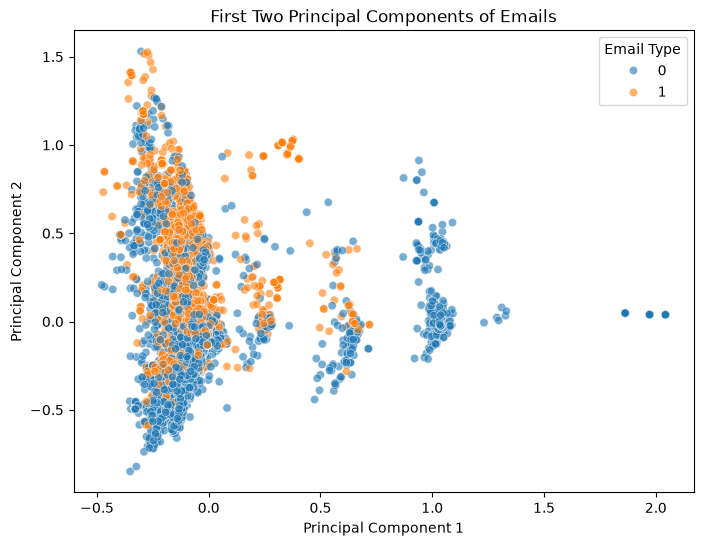

In [ ]:
# Q3: Perform PCA with 2 components and plot
from sklearn.decomposition import PCA

# fitting PCA with 2 components on the token matrix
pca_2 = PCA(n_components=2, random_state=100)
Z_2 = pca_2.fit_transform(X)

pca_df = pd.DataFrame({
    'PC1': Z_2[:, 0],
    'PC2': Z_2[:, 1],
    'Email Type': y
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', alpha=0.6)
plt.title("First Two Principal Components of Emails")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

Looking at the scatterplot of the first two principal components, there is a noticeable pattern separating the two groups. The phishing scam emails (`Email Type` = 1) tend to cluster much more tightly together near one side of the plot, whereas the legitimate emails (`Email Type` = 0) are spread out much more widely along both Principal Component 1 and even some at Principal Component 2. While there is still overlap near the origin, the legitimate emails reach further right horizontally in the chart 

# Q4:

In [16]:
pca_2610 = PCA(n_components=2610, random_state=100)

# fit PCA on the training set and transform both training and test sets
Z_train = pca_2610.fit_transform(X_train)
Z_test = pca_2610.transform(X_test)

# run da linear regression on the principal components
reg_pca = LinearRegression().fit(Z_train, y_train)

r2_pca_train = reg_pca.score(Z_train, y_train)
r2_pca_test = reg_pca.score(Z_test, y_test)

print(f"PCA Regression Training R^2: {r2_pca_train:.4f}")
print(f"PCA Regression Test R^2: {r2_pca_test:.4f}")

PCA Regression Training R^2: 0.7673
PCA Regression Test R^2: 0.6597


Using the first 2,610 principal components, the training $R^2$ is **0.7673** and the test $R^2$ is **0.6597**. Compared to the standard linear regression in Q2 (which had a training $R^2$ of 0.7680 and a test $R^2$ of 0.6588), the principal component regression is basically the same training fit (`0.7673` vs. `0.7680`) and (`0.6597` vs. `0.6588`), even after dropping 101 dimensions.

# Q5:

In high-dimensional text data, many words frequently appear together, creating severe multicollinearity among the 2,711 token features. This means that standard linear regression isn't as effective and it struggles a lot, such as unstable coefficients, massive variance, and model overfitting.

Using Principal Components Analysis (PCA) transforms the original correlated tokens into a set of orthogonal (completely uncorrelated) components ordered by how much variance they explain in $X$. By keeping the first 2,610 components and dropping the last ~101 components which is just mostly noise and near-collinearities, it helps to regularize the regression and mitigate the issue.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [12]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]